# 05 · Model training & evaluation
Training: `python -m airsense.ml.train` (≈4 min, 24 direct horizons). This notebook loads the versioned results of the active model.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT / "backend"))
import pandas as pd, numpy as np, json
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from IPython.display import Image, display

In [2]:
reg = json.loads((ROOT/'models/registry.json').read_text()); reg

{'active': 'v20261122-6e6d1a',
 'versions': [{'version': 'v20261122-6e6d1a',
   'created_at': '2026-11-22T20:44:01.986337+00:00',
   'path': 'v20261122-6e6d1a/best_model.pkl',
   'data_hash': '6e6d1a97090b',
   'horizons': 24}]}

In [3]:
t = pd.read_csv(ROOT/'reports/model_results/test_metrics.csv')
t[t.horizon.isin([1,3,6,12,24])].pivot_table(index='horizon', columns='model', values='mae').round(2)

model,CAMS global (Copernicus),Linear Regression,Persistence,Random Forest,Seasonal naive (24h),XGBoost
horizon,,,,,,
1,19.30,6.11,5.89,5.49,13.39,5.34
3,19.27,10.30,11.87,9.29,13.34,9.47
6,19.31,12.10,16.33,11.21,13.40,10.98
12,19.47,12.61,18.57,11.98,13.49,12.00
24,19.51,12.14,13.51,11.47,13.51,12.01


In [4]:
t[t.model=='XGBoost'][['horizon','mae','rmse','r2','skill_vs_persistence','interval_coverage_80']].round(3)

,horizon,mae,rmse,r2,skill_vs_persistence,interval_coverage_80
4,1,5.340,16.746,0.860,0.094,0.817
9,2,8.164,28.628,0.589,0.132,0.822
15,3,9.467,30.090,0.544,0.203,0.802
20,4,10.016,30.587,0.526,0.270,0.791
25,5,10.615,31.533,0.500,0.302,0.781
31,6,10.984,31.943,0.490,0.328,0.775
36,7,11.457,32.639,0.473,0.337,0.766
41,8,11.621,33.038,0.463,0.350,0.772
46,9,11.679,32.651,0.472,0.359,0.766
51,10,11.642,32.545,0.482,0.367,0.773


In [5]:
print(json.dumps(json.loads((ROOT/'reports/model_results/sarima_daily.json').read_text())['mean'], indent=1))

{
 "sarima": {
  "mean_mae": 9.56142396678485
 },
 "persistence": {
  "mean_mae": 8.477996551486127
 }
}


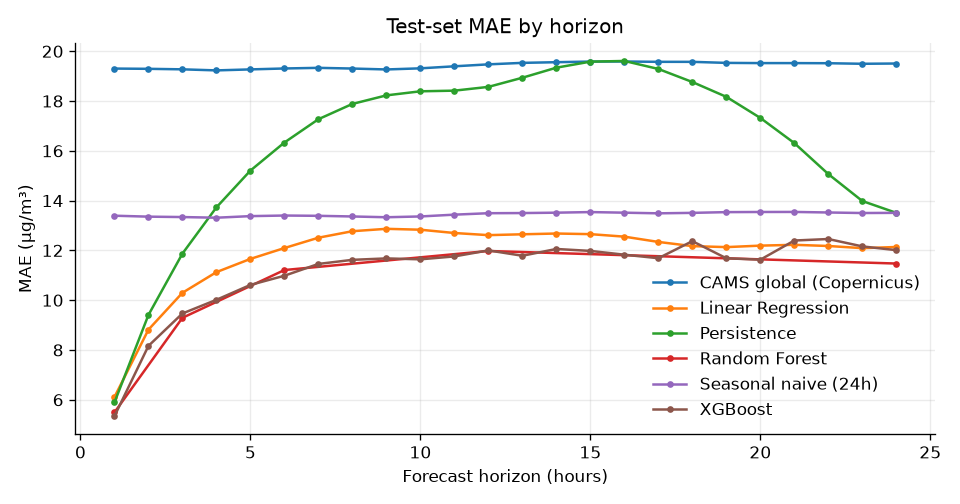

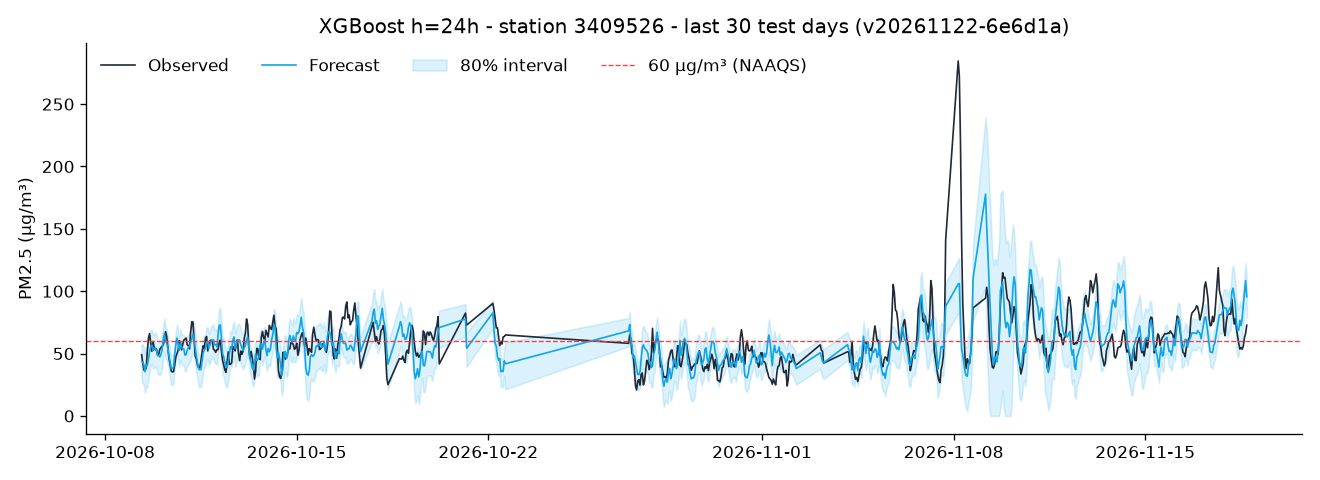

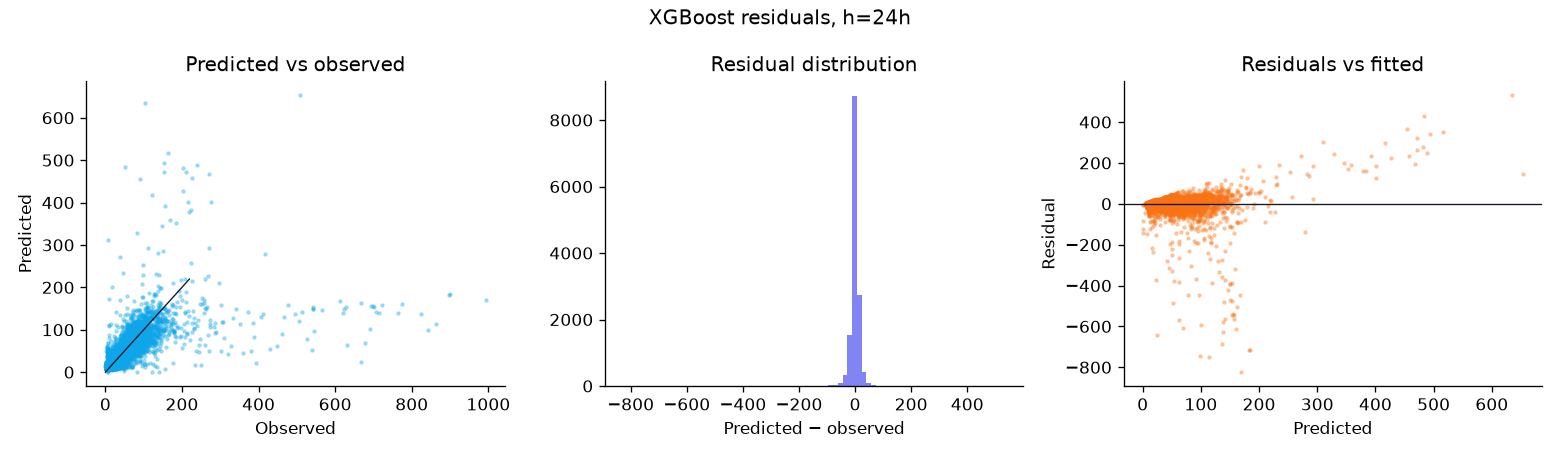

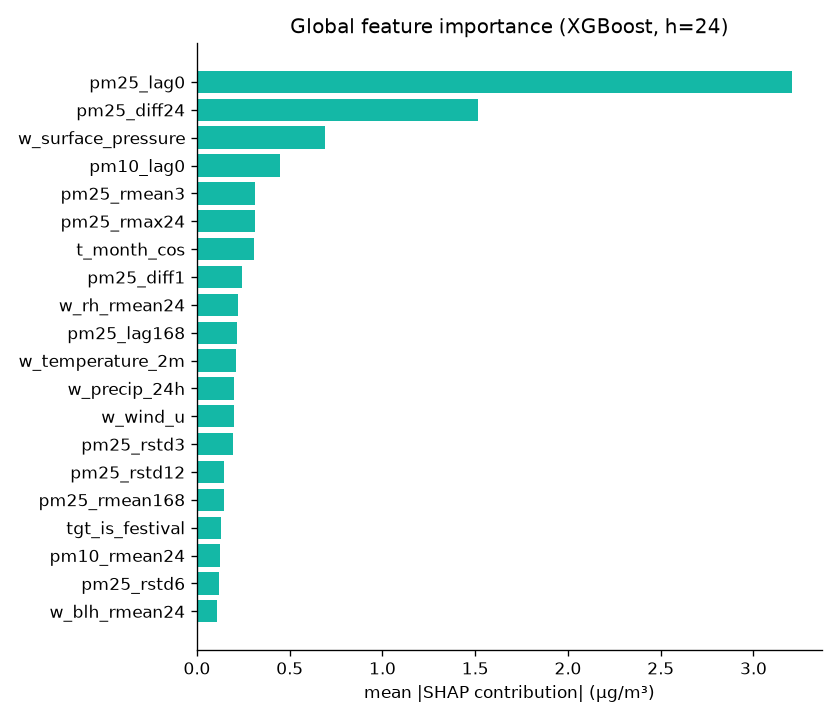

In [6]:
for f in ['model_mae_by_horizon.png','actual_vs_pred_h24.png','residuals_h24.png','feature_importance_h24.png']:
    display(Image(filename=str(ROOT/'reports/figures'/f), width=820))

**Conclusion:** XGBoost beats persistence at all 24 horizons on the unseen chronological test window (mean skill ≈ 29 %), 80 % conformal intervals achieve 77–82 % coverage, and station-level ML is far more accurate than the CAMS grid model. SARIMA on daily means does not beat daily persistence.